# AutoML experiments (FLAML)

**Goal:** after the hand-built experiments, see whether an automated search over model families and
hyperparameters finds something we missed. The assignment allows AutoML once a manual approach is
done.

**Tool:** [FLAML](https://github.com/microsoft/FLAML) (Microsoft). It searches LightGBM, XGBoost,
random forest, Extra Trees and L1 logistic regression within a time budget, using a cost-aware
search that tries cheap configurations first. We chose it over AutoGluon because it is lightweight
and accepts **our own CV splitters**, so it optimises the same objective as our manual experiments.

**What we already know:**
- **Unseen subjects** (E, J; 54% of test): no model beats predicting all 1s. Grouped AUC is
  0.50–0.59.
- **Known subjects** (46% of test): the hybrid features (per-subject z-score + subject one-hot) work.
  The best so far is a random forest + gradient boosting blend at **0.870** test-weighted accuracy
  (all 1s: 0.843).

**Risk to watch:** AutoML tries hundreds of configurations against the same 5 folds. With only 11
subjects, the "best" grouped configuration may just fit the way those folds happen to split. We
re-check it on a different split (leave-one-subject-out).

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from flaml import AutoML
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")  # LightGBM / FLAML info-level warnings
RANDOM_STATE = 42
TIME_UNSEEN = 300   # seconds of AutoML search for experiment 1
TIME_KNOWN = 600    # seconds of AutoML search for experiment 2
ESTIMATORS = ["lgbm", "xgboost", "rf", "extra_tree", "lrl1"]

## 1. Load data and build features (same as `gradient_boosting.ipynb` section 2)

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")
y = train["output"]
groups = train["subject"].to_numpy(dtype=object)  # FLAML needs a plain numpy array for groups

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    return pd.get_dummies(X, columns=["state"], dtype=int)

X_raw = prep(train)
X_test_raw = prep(test).reindex(columns=X_raw.columns, fill_value=0)
const_cols = X_raw.columns[X_raw.nunique() <= 1]
X_raw = X_raw.drop(columns=const_cols)
X_test_raw = X_test_raw.drop(columns=const_cols)
sensor_cols = [c for c in X_raw.columns if c[0] in "xyz" and c[1:].isdigit()]

both = pd.concat([X_raw, X_test_raw], ignore_index=True)
subj_all = pd.concat([train.subject, test.subject], ignore_index=True)
g = both[sensor_cols].groupby(subj_all.values)
both[sensor_cols] = ((both[sensor_cols] - g.transform("mean")) / g.transform("std").replace(0, np.nan)).fillna(0)
subj_onehot = pd.get_dummies(subj_all, prefix="subj", dtype=int).reindex(
    columns=[f"subj_{s}" for s in sorted(train.subject.unique())], fill_value=0)
both = pd.concat([both, subj_onehot], axis=1)
X_hyb = both.iloc[:len(train)].reset_index(drop=True)
X_test_hyb = both.iloc[len(train):].reset_index(drop=True)

known = test.subject.isin(train.subject.unique()).values
test_mix = test.subject[known].value_counts(normalize=True)
print(f"raw: {X_raw.shape[1]} features; hybrid: {X_hyb.shape[1]} features; known-subject test rows: {known.mean():.1%}")

raw: 564 features; hybrid: 575 features; known-subject test rows: 45.7%


## 2. Evaluation helpers

Same known-subject scoring as the other notebooks: stratified out-of-fold probabilities, a tuned
threshold, and per-subject accuracy re-weighted to the test mix. AutoML optimises **ROC AUC**, not
accuracy, because accuracy at a 0.5 threshold barely moves when a model rarely predicts class 0. We
turn the ranking into accuracy with the threshold afterwards.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
thresholds = np.linspace(0.3, 0.8, 51)

def test_weighted_acc(pred):
    per_subj = pd.Series(pred == y.values).groupby(groups).mean()
    return (per_subj.reindex(test_mix.index) * test_mix).sum()

def known_subject_scores(p):
    accs = [accuracy_score(y, (p >= t).astype(int)) for t in thresholds]
    t = thresholds[int(np.argmax(accs))]
    pred = (p >= t).astype(int)
    return {"threshold": t, "strat_acc": accuracy_score(y, pred),
            "f1_macro": f1_score(y, pred, average="macro"), "auc": roc_auc_score(y, p),
            "test_weighted_acc": test_weighted_acc(pred)}

def run_automl(X, split, time_budget, **kw):
    automl = AutoML()
    automl.fit(X, y, task="classification", metric="roc_auc", eval_method="cv", split_type=split,
               time_budget=time_budget, estimator_list=ESTIMATORS, seed=RANDOM_STATE, verbose=0, **kw)
    print(f"Best: {automl.best_estimator}  CV AUC = {1 - automl.best_loss:.4f}")
    print("Config:", {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                      for k, v in automl.best_config.items()})
    print("Best CV AUC per model family:",
          {k: round(1 - v, 4) for k, v in automl.best_loss_per_estimator.items() if v is not None and np.isfinite(v)})
    return automl

## 3. Experiment 1: AutoML on unseen subjects (raw features, GroupKFold)

**Hypothesis:** AutoML won't find transferable signal either. Its best GroupKFold AUC may look
better than our hand-tuned models (0.54–0.59), because it searches so many configurations against
the same 5 folds. When the chosen configuration is re-scored with **leave-one-subject-out** (11
different folds), its AUC should fall back toward 0.5 and its accuracy should not beat all 1s.

In [4]:
automl_unseen = run_automl(X_raw, gkf, TIME_UNSEEN, groups=groups)

Best: extra_tree  CV AUC = 0.5885
Config: {'n_estimators': 64, 'max_leaves': 27, 'max_features': 0.6746, 'criterion': np.str_('entropy')}
Best CV AUC per model family: {'lgbm': 0.5775, 'xgboost': 0.5823, 'rf': 0.5773, 'extra_tree': 0.5885, 'lrl1': 0.4949}


In [5]:
logo_model = clone(automl_unseen.model.estimator)
p_logo = cross_val_predict(logo_model, X_raw, y, cv=LeaveOneGroupOut(), groups=groups, method="predict_proba")[:, 1]

per_subj = pd.DataFrame({"y": y.values, "p": p_logo, "subject": groups})
subj_auc = pd.Series({s: roc_auc_score(d.y, d.p) for s, d in per_subj.groupby("subject") if d.y.nunique() > 1})
pred_logo = (p_logo >= 0.5).astype(int)
print(f"Leave-one-subject-out: pooled AUC = {roc_auc_score(y, p_logo):.3f}, "
      f"mean within-subject AUC = {subj_auc.mean():.3f}")
print(f"Accuracy at 0.5 = {accuracy_score(y, pred_logo):.4f} vs all 1s = {(y == 1).mean():.4f}; "
      f"predicts class 0 for {(pred_logo == 0).mean():.1%} of rows")
subj_auc.round(3).rename("within-subject AUC (held out)").to_frame().T

Leave-one-subject-out: pooled AUC = 0.410, mean within-subject AUC = 0.563
Accuracy at 0.5 = 0.8445 vs all 1s = 0.8449; predicts class 0 for 0.2% of rows


,A,B,C,D,F,G,H,I,L,M
within-subject AUC (held out),0.686,0.62,0.475,0.546,0.523,0.538,0.525,0.757,0.56,0.4


**Interpretation:** the hypothesis held. After about 5 minutes of search, AutoML's best GroupKFold
AUC is **0.589** (Extra Trees, 64 trees with 27 leaves). That is the same as our best hand-tuned
MLP (0.59) and better than every other family. LightGBM, XGBoost and RF all reach 0.58, and L1
logistic regression scores 0.49. On **leave-one-subject-out**, though:
- the pooled AUC falls to **0.41**, below random, and accuracy is at the all-1s level (0.8445 vs
  0.8449), with only 0.2% of rows predicted as 0;
- the **mean within-subject AUC is 0.56**. Inside a new subject the model ranks rows slightly
  better than chance (I: 0.76, A: 0.69, B: 0.62; M: 0.40). The pooled AUC is below 0.5 because
  its probabilities sit at the wrong *level* for each subject.

So AutoML doesn't change the conclusion for E and J: a searched configuration doesn't transfer. The
within-subject AUC of 0.56 is a small lead: a model that ranks rows *within* each new subject
might help if we could estimate each unseen subject's class-0 rate some other way.

## 4. Experiment 2: AutoML in the hybrid setup (known subjects)

**Hypothesis:** on the hybrid features AutoML will match or slightly beat our hand-tuned forest and
boosting (AUC about 0.865). LightGBM or XGBoost with tuned leaf counts, column subsampling and
regularisation is the obvious candidate. Adding its probabilities to the forest + boosting blend may
add a little more.

References recomputed on the same folds:
- the forest (500 trees);
- gradient boosting with the tuned settings from `gradient_boosting.ipynb` §6, run for **800 rounds
  without early stopping**, which a training-length check showed is better than early stopping
  (0.870 vs 0.864).

**Caveat:** AutoML chooses its configuration on these same stratified folds, so its numbers are a
little more optimistic than the references'.

In [6]:
automl_known = run_automl(X_hyb, skf, TIME_KNOWN)

Best: extra_tree  CV AUC = 0.8901
Config: {'n_estimators': 701, 'max_features': 0.119, 'max_leaves': 575, 'criterion': np.str_('entropy')}
Best CV AUC per model family: {'lgbm': 0.8766, 'xgboost': 0.867, 'rf': 0.8612, 'extra_tree': 0.8901, 'lrl1': 0.7548}


In [7]:
automl_model = clone(automl_known.model.estimator)
rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=800, early_stopping=False, max_leaf_nodes=31,
                                     l2_regularization=1.0, max_features=0.3, random_state=RANDOM_STATE)

oof = {name: cross_val_predict(m, X_hyb, y, cv=skf, method="predict_proba")[:, 1]
       for name, m in [("random forest", rf), ("gradient boosting (800 rounds)", hgb),
                       (f"AutoML: {automl_known.best_estimator}", automl_model)]}
names = list(oof)
oof["blend rf + hgb"] = (oof[names[0]] + oof[names[1]]) / 2
oof["blend rf + hgb + AutoML"] = (oof[names[0]] + oof[names[1]] + oof[names[2]]) / 3

rows = {"all 1s": {"threshold": np.nan, "strat_acc": (y == 1).mean(), "f1_macro": 0.458, "auc": 0.5,
                   "test_weighted_acc": test_weighted_acc(np.ones(len(y), dtype=int))}}
rows.update({name: known_subject_scores(p) for name, p in oof.items()})
known_table = pd.DataFrame(rows).T
print("Correlation of OOF probabilities:")
print(pd.DataFrame({k: oof[k] for k in names}).corr().round(3))
known_table.round(4)

Correlation of OOF probabilities:
                                random forest  gradient boosting (800 rounds)  \
random forest                           1.000                           0.814   
gradient boosting (800 rounds)          0.814                           1.000   
AutoML: extra_tree                      0.960                           0.828   

                                AutoML: extra_tree  
random forest                                0.960  
gradient boosting (800 rounds)               0.828  
AutoML: extra_tree                           1.000  


,threshold,strat_acc,f1_macro,auc,test_weighted_acc
all 1s,NaN,0.8449,0.4580,0.5000,0.8426
random forest,0.58,0.8695,0.7212,0.8650,0.8666
gradient boosting (800 rounds),0.69,0.8728,0.7146,0.8678,0.8700
AutoML: extra_tree,0.57,0.8787,0.7397,0.8899,0.8759
blend rf + hgb,0.65,0.8733,0.7236,0.8689,0.8704
blend rf + hgb + AutoML,0.59,0.8754,0.7168,0.8815,0.8726


Best for known subjects: AutoML: extra_tree (threshold 0.57)


,A,B,C,D,F,G,H,I,K,L,M
acc,0.974,0.895,0.762,0.940,0.815,0.649,0.862,0.962,1.000,0.946,0.791
all_1s_acc,0.971,0.860,0.756,0.938,0.779,0.492,0.862,0.962,1.000,0.912,0.709
test_share,0.075,0.099,0.090,0.105,0.076,0.111,0.042,0.157,0.087,0.090,0.070


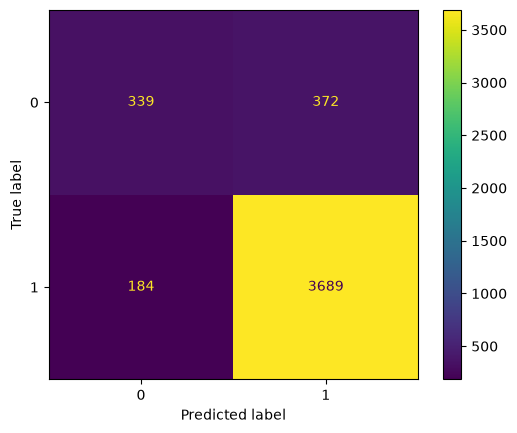

In [8]:
final_name = known_table.drop("all 1s").test_weighted_acc.astype(float).idxmax()
t_final = known_table.loc[final_name, "threshold"]
print(f"Best for known subjects: {final_name} (threshold {t_final:.2f})")
pred = (oof[final_name] >= t_final).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y, pred)).plot()
pd.DataFrame({"acc": pd.Series(pred == y.values).groupby(groups).mean(),
              "all_1s_acc": (y == 1).groupby(groups).mean(),
              "test_share": test_mix}).round(3).T

**Interpretation:** the hypothesis was partly right, but the winner was unexpected. AutoML's best
model is **Extra Trees** with **701 trees, very large trees (up to 575 leaves) and few features per
split (12%)**, not LightGBM or XGBoost. It is the best known-subject model so far:
- **0.876** test-weighted accuracy vs 0.870 for the forest + boosting blend, and **AUC 0.890** vs
  0.869, the largest AUC gain since the hybrid features were introduced;
- improvements on most subjects that have class-0 rows (B 0.895, M 0.791, L 0.946, F 0.815,
  G 0.649);
- adding it to the forest + boosting blend makes things *worse* (0.873) than Extra Trees alone. It
  is 0.96 correlated with the forest, so the blend mostly dilutes it with weaker versions of the
  same thing.

Our own Extra Trees in `random_forest.ipynb` §7 was only tried on *unseen* subjects, with heavy
regularisation (`min_samples_leaf=20`). Here, with big trees and strong feature subsampling, it
works best.

**Robustness check (run separately, not in this notebook):** AutoML chose its configuration on the
same stratified folds it is scored on above, so we re-scored the fixed configuration
(`ExtraTreesClassifier(n_estimators=701, max_features=0.119, max_leaf_nodes=575,
criterion="entropy")`) against the forest and boosting on **two fresh 5-fold splits**
(random_state 7 and 123):

| | rf | hgb (800) | rf + hgb | **Extra Trees** | rf + hgb + ET |
|---|---|---|---|---|---|
| seed 7: acc / AUC | 0.866 / 0.865 | 0.862 / 0.864 | 0.865 / 0.866 | **0.871 / 0.884** | 0.867 / 0.878 |
| seed 123: acc / AUC | 0.865 / 0.866 | 0.865 / 0.866 | 0.865 / 0.869 | **0.873 / 0.889** | 0.869 / 0.881 |

Extra Trees is best on both splits, by +0.6–0.9 pts accuracy and +0.02 AUC over the forest +
boosting blend. The gain is real, not a result of fitting one particular split. (The blend's 0.870
on the original folds also turns out to be slightly optimistic; it is 0.865 on fresh folds.)

## 5. Feature importance of the AutoML model

Permutation importance on one stratified validation fold, scored by AUC, as in
`gradient_boosting.ipynb` §8, so the two can be compared directly.

**Hypothesis:** if AutoML found the same signal as the forest and boosting, the same features will
rank at the top (`z47`, `x40`, `phase`, `subj_G`).

Features with importance > 0.002: 9


subj_G    0.0433
subj_K    0.0162
phase     0.0076
subj_A    0.0053
subj_M    0.0051
x40       0.0031
x3        0.0029
subj_D    0.0028
subj_C    0.0025
subj_L    0.0014
dtype: float64

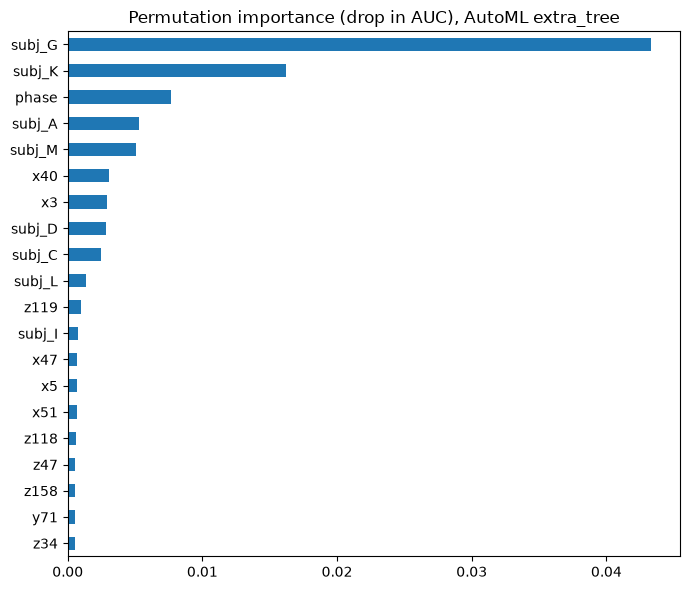

In [9]:
tr_idx, va_idx = next(skf.split(X_hyb, y))
imp_model = clone(automl_known.model.estimator).fit(X_hyb.iloc[tr_idx], y.iloc[tr_idx])
perm = permutation_importance(imp_model, X_hyb.iloc[va_idx], y.iloc[va_idx], scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_hyb.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6), title=f"Permutation importance (drop in AUC), AutoML {automl_known.best_estimator}")
plt.tight_layout()
print(f"Features with importance > 0.002: {(perm_imp > 0.002).sum()}")
perm_imp.head(10).round(4)

**Interpretation:** this hypothesis was wrong in an informative way. The Extra Trees model leans on
**subject identity** much more than gradient boosting did. `subj_G` (0.043) is 4× larger than
any sensor feature, and seven subject columns are in the top 10. Then come `phase` (0.008) and only
two sensor features, `x40` (0.003, also in boosting's top 2) and `x3`. So most of its gain comes
from learning each subject's class-0 rate more precisely, plus a little sensor signal. That is a
valid strategy for known subjects. It also explains why none of this transfers to E and J.

## 6. Hybrid submission

Fit the best known-subject option on all training rows, predict the known-subject test rows with
its tuned threshold, and set E and J to 1.

In [10]:
models = {names[0]: rf, names[1]: hgb, names[2]: automl_model}
members = {"blend rf + hgb": names[:2], "blend rf + hgb + AutoML": names}.get(final_name, [final_name])
p_test = np.mean([clone(models[n]).fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1] for n in members], axis=0)

automl_hybrid = sample_solution.copy()
automl_hybrid["output"] = 1
automl_hybrid.loc[known, "output"] = (p_test >= t_final).astype(int)
automl_hybrid.to_csv("submission_automl_hybrid.csv", index=False)

prev = pd.read_csv("submission_gb_hybrid.csv")
print(f"Predicted class 0: {(automl_hybrid.output[known] == 0).mean():.1%} of known-subject rows "
      f"(rf + hgb blend submission: {(prev.output[known] == 0).mean():.1%})")
print(f"Agreement with submission_gb_hybrid.csv on known-subject rows: "
      f"{(automl_hybrid.output[known] == prev.output[known]).mean():.1%}")
(automl_hybrid.output[known] == 0).groupby(test.subject[known].values).mean().round(3).rename("pred_frac_0")

Predicted class 0: 11.8% of known-subject rows (rf + hgb blend submission: 9.2%)
Agreement with submission_gb_hybrid.csv on known-subject rows: 94.9%


A    0.017
B    0.090
C    0.113
D    0.000
F    0.167
G    0.670
H    0.030
I    0.000
K    0.000
L    0.028
M    0.091
Name: pred_frac_0, dtype: float64

**Interpretation:** the Extra Trees hybrid predicts class 0 for **11.8%** of known-subject rows
(blend submission: 9.2%), mainly G (67%), F (17%), C (11%), B and M (9%). It agrees with
`submission_gb_hybrid.csv` on 95% of those rows. Expected gain: about +3.3 pts on known-subject rows
vs all 1s on the original folds and +2.8–3.1 on fresh folds, so roughly **+1.3–1.5 pts overall**.
That is about 0.3–0.4 pts more than the forest + boosting blend. **This is the submission to try
next.**

## Summary and next steps

**Result:**

| Known-subject model | Test-weighted acc (CV folds) | Acc, fresh folds (2 seeds) | AUC |
|---|---|---|---|
| all 1s | 0.843 | — | 0.50 |
| random forest | 0.867 | 0.865–0.866 | 0.865 |
| gradient boosting, 800 rounds | 0.870 | 0.862–0.865 | 0.868 |
| blend rf + hgb | 0.870 | 0.865 | 0.869 |
| **AutoML: Extra Trees** | **0.876** | **0.871–0.873** | **0.890** |

**What we learned:**
- **Unseen subjects:** AutoML matches our best grouped AUC (0.59), and leave-one-subject-out shows it
  doesn't transfer (pooled AUC 0.41, accuracy = all 1s). Searching harder doesn't fix the problem.
  It needs different features.
- **Known subjects:** AutoML found a better model family: Extra Trees with big trees and strong
  feature subsampling. The gain holds on fresh folds and is the largest single improvement since the
  hybrid features.
- The model relies mostly on subject identity (`subj_G`, `subj_K`) and `phase`, with a little signal
  from `x40` and `x3`.

**Submission:** `submission_automl_hybrid.csv` (Extra Trees for known subjects, 1 for E/J). Expected
gain is about +1.3–1.5 pts overall vs all 1s.

**Next steps:**
1. Submit it and compare with `submission_gb_hybrid.csv`.
2. For E and J: experiment 1 showed some within-subject ranking on new subjects (mean AUC 0.56). One
   idea is to predict class 0 for the lowest-scoring *k*% of each unseen subject's rows, choosing *k*
   with leave-one-subject-out. It's risky, because the class-0 rate varies from 0% to 51% across
   subjects.
3. Reproducibility: FLAML's search depends on the time budget, so a re-run on a different machine may
   choose a different configuration. The chosen settings are written down in §4, so the model can
   be rebuilt directly as `ExtraTreesClassifier(n_estimators=701, max_features=0.119,
   max_leaf_nodes=575, criterion="entropy")`.

*Runtime:* about 19 minutes (15 of them AutoML search).